# 02 · Что покупают и как долго ждут доставку

Рассмотрим заказ с точки зрения покупателя. Нас интересуют сумма товаров, плата за доставку, срок ожидания и оценка после покупки. В основной выборке только заказы со статусом `delivered`. Дата группировки продаж — дата покупки, валюта — бразильский реал (R$). Перед запуском загрузи базу по инструкции в README. Витрина сначала суммирует позиции и платежи внутри заказа, затем выбирает последний отзыв. Благодаря этому строки платежей не умножают сумму товаров.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Используем те же настройки подключения, что и загрузчик CSV.
sys.path.insert(0, str(ROOT / "sql"))
from connection import database_url

engine = create_engine(database_url(ROOT).replace("postgresql://", "postgresql+psycopg2://", 1))
query = """
    SELECT order_id, order_purchase_timestamp, order_delivered_customer_date, order_estimated_delivery_date,
           revenue, freight_value, item_count, payment_value, review_score
    FROM olist.order_mart
    WHERE order_status = 'delivered'
    ORDER BY order_id
"""
orders = pd.read_sql(query, engine, parse_dates=["order_purchase_timestamp", "order_delivered_customer_date",
                                               "order_estimated_delivery_date"])
assert orders["order_id"].is_unique
print(f"{len(orders):,} доставленных заказов")

96,478 доставленных заказов


## Собираем признаки заказа

Стоимость для покупателя складывается из товаров и доставки. Доля доставки показывает, какая часть этой суммы приходится на пересылку. Опоздание считаем по календарным датам: получение в любой час обещанного дня считается доставкой вовремя.

In [2]:
orders["order_total"] = orders["revenue"] + orders["freight_value"]
orders["freight_share"] = orders["freight_value"].div(orders["order_total"].where(orders["order_total"] > 0))
receipt = orders["order_delivered_customer_date"].dt.normalize()
purchase = orders["order_purchase_timestamp"].dt.normalize()
promise = orders["order_estimated_delivery_date"].dt.normalize()
orders["delivery_days"] = (receipt - purchase).dt.days
orders["delay_days"] = (receipt - promise).dt.days
orders["is_late"] = orders["delay_days"].astype("Int64") > 0
orders["month"] = orders["order_purchase_timestamp"].dt.to_period("M")
orders["weekday"] = orders["order_purchase_timestamp"].dt.day_of_week + 1  # 1 = понедельник
orders[["revenue", "freight_value", "order_total", "freight_share", "delivery_days", "delay_days", "is_late"]].head()

,revenue,freight_value,order_total,freight_share,delivery_days,delay_days,is_late
0,58.90,13.29,72.19,0.184098,7.0,-9.0,False
1,239.90,19.93,259.83,0.076704,16.0,-3.0,False
2,199.00,17.87,216.87,0.082400,8.0,-14.0,False
3,12.99,12.79,25.78,0.496121,6.0,-6.0,False
4,199.90,18.14,218.04,0.083196,25.0,-16.0,False


## Пропуски и необычно большие значения

У доставленного заказа иногда отсутствует дата вручения, отзыв или запись об оплате. Для каждого графика берём строки, в которых известны нужные ему поля. Отсутствующую оценку нельзя заменить нулём, потому что шкала начинается с одного. При неизвестной дате оставляем срок и флаг опоздания пустыми.

In [3]:
features = ["revenue", "freight_value", "order_total", "freight_share", "item_count", "payment_value",
            "delivery_days", "delay_days", "is_late", "review_score", "month", "weekday"]
orders[features].isna().sum().rename("Строк с пропуском").to_frame()

,Строк с пропуском
revenue,0
freight_value,0
order_total,0
freight_share,0
item_count,0
payment_value,1
delivery_days,8
delay_days,8
is_late,8
review_score,646


In [4]:
metrics = orders[["revenue", "freight_value", "delivery_days", "review_score"]]
summary = metrics.describe(percentiles=[.25, .5, .75, .90, .95, .99]).T
iqr = summary["75%"] - summary["25%"]
low = summary["25%"] - 1.5 * iqr
high = summary["75%"] + 1.5 * iqr
summary["за границей 1,5 IQR"] = (metrics.lt(low) | metrics.gt(high)).sum()
summary.round(2)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max,"за границей 1,5 IQR"
revenue,96478.0,137.04,209.05,0.85,45.90,86.57,149.90,269.00,399.00,990.00,13440.00,7659
freight_value,96478.0,22.79,21.56,0.00,13.85,17.17,24.02,39.38,54.78,104.24,1794.96,9697
delivery_days,96470.0,12.50,9.56,0.00,7.00,10.00,16.00,23.00,29.00,46.00,210.00,4729
review_score,95832.0,4.16,1.28,1.00,4.00,5.00,5.00,5.00,5.00,5.00,5.00,12273


Цена отдельной позиции и товарная сумма всего заказа отвечают на разные вопросы. Проверим цены непосредственно в `order_items`. Медианная цена одной позиции — 74,90 R$, медианная сумма товаров в одном доставленном заказе — 86,57 R$.

In [5]:
item_prices = pd.read_sql("""
    SELECT i.price
    FROM olist.order_items i JOIN olist.orders o ON i.order_id = o.order_id
    WHERE o.order_status = 'delivered'
""", engine)["price"]

q1, q3 = item_prices.quantile([.25, .75])
iqr_price = q3 - q1
outside = (item_prices < q1 - 1.5 * iqr_price) | (item_prices > q3 + 1.5 * iqr_price)
print(f"Позиций за границами 1,5 IQR: {outside.sum():,} из {len(item_prices):,}")
item_prices.describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(2).to_frame("Цена позиции, R$")

Позиций за границами 1,5 IQR: 8,162 из 110,197


,"Цена позиции, R$"
count,110197.00
mean,119.98
std,182.30
min,0.85
25%,39.90
50%,74.90
75%,134.17
90%,228.94
95%,349.00
99%,887.08


Границы Тьюки (1,5 межквартильного размаха) помогают заметить суммы и сроки для проверки. Дорогой многопозиционный заказ может быть реальным, поэтому в расчётах оставляем весь диапазон. Для дискретной шкалы 1–5 допустимость проверяем границами самой шкалы. Число за пределами IQR само по себе не повод отбрасывать отзыв.

## 1. В какие месяцы покупали больше

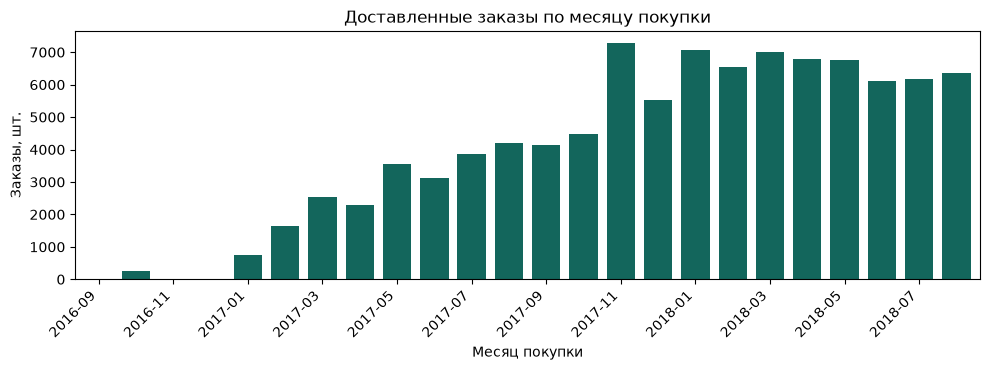

In [6]:
monthly = orders.groupby("month").size()
# В начале выгрузки есть месяцы без заказов. Вставляем их в календарь.
monthly = monthly.reindex(pd.period_range(monthly.index.min(), monthly.index.max(), freq="M"), fill_value=0)
monthly.index = monthly.index.astype(str)
ax = monthly.plot(kind="bar", figsize=(10, 3.8), color="#13665c", width=.76)
ax.set(title="Доставленные заказы по месяцу покупки", xlabel="Месяц покупки", ylabel="Заказы, шт.")
ax.set_xticks(range(0, len(monthly), 2), monthly.index[::2], rotation=45, ha="right")
plt.tight_layout()
plt.show()

Пик пришёлся на ноябрь 2017 года — 7 289 заказов. По нескольким покупкам в крайних месяцах нельзя уверенно судить о темпе роста.

## 2. Сколько дней занимает доставка

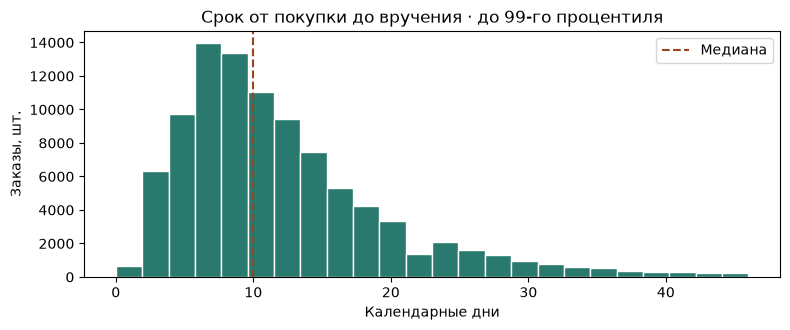

In [7]:
days = orders["delivery_days"].dropna()
fig, ax = plt.subplots(figsize=(8, 3.4))
# Граница нужна только для читаемости. Полный диапазон приведён в таблице выше.
limit = days.quantile(.99)
ax.hist(days[days <= limit], bins=24, color="#29796e", edgecolor="white")
ax.axvline(days.median(), color="#9d421e", linestyle="--", label="Медиана")
ax.set(title="Срок от покупки до вручения · до 99-го процентиля",
       xlabel="Календарные дни", ylabel="Заказы, шт.")
ax.legend()
plt.tight_layout()
plt.show()

Половину заказов доставили за 10 дней или быстрее, при этом правый хвост достигает 210 дней. График показывает основную часть диапазона.

## 3. Какие оценки получают заказы с опозданием

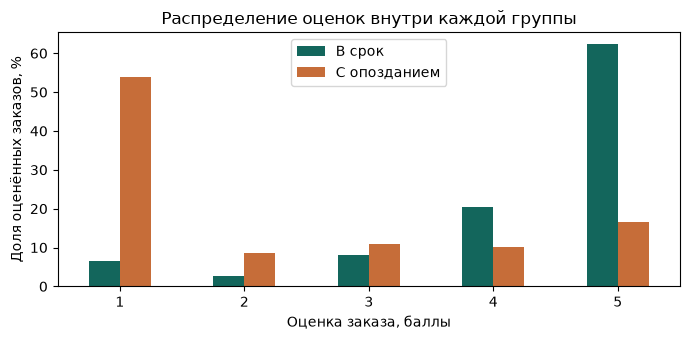

,count,mean,median
is_late,,,
False,89443,4.29,5.0
True,6381,2.27,1.0


In [8]:
rated = orders.dropna(subset=["is_late", "review_score"])
score_share = pd.crosstab(rated["is_late"], rated["review_score"], normalize="index")
score_share.columns = score_share.columns.astype(int)
score_share.index = score_share.index.map({False: "В срок", True: "С опозданием"})
ax = (score_share * 100).T.plot(kind="bar", color=["#13665c", "#c66d39"], figsize=(7, 3.5))
ax.set(title="Распределение оценок внутри каждой группы", xlabel="Оценка заказа, баллы",
       ylabel="Доля оценённых заказов, %")
ax.tick_params(axis="x", labelrotation=0)
ax.legend(title="")
plt.tight_layout()
plt.show()
rated.groupby("is_late")["review_score"].agg(["count", "mean", "median"]).round(2)

Среди заказов с отзывом медианная оценка равна 5 при доставке в срок и 1 при опоздании. По одному отзыву на заказ берём последний ответ покупателя.

## 4. Какие категории приносят больше оборота

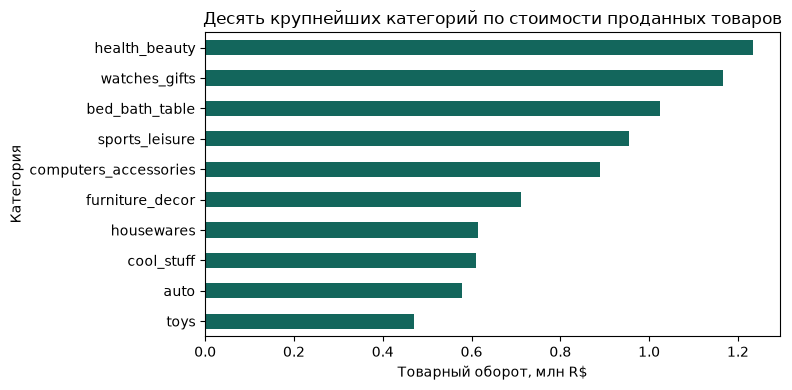

In [9]:
category_sql = """
    SELECT COALESCE(t.product_category_name_english, p.product_category_name, 'unknown') AS category_name,
           SUM(i.price) AS revenue
    FROM olist.order_items i
    JOIN olist.orders o ON i.order_id = o.order_id
    JOIN olist.products p ON i.product_id = p.product_id
    LEFT JOIN olist.category_translation t ON p.product_category_name = t.product_category_name
    WHERE o.order_status = 'delivered'
    GROUP BY COALESCE(t.product_category_name_english, p.product_category_name, 'unknown')
    ORDER BY revenue DESC
    LIMIT 10
"""
top = pd.read_sql(category_sql, engine).sort_values("revenue")
ax = top.set_index("category_name")["revenue"].div(1_000_000).plot.barh(color="#13665c", figsize=(8, 4))
ax.set(title="Десять крупнейших категорий по стоимости проданных товаров",
       xlabel="Товарный оборот, млн R$", ylabel="Категория")
plt.tight_layout()
plt.show()

Лидер по стоимости проданных товаров — `health_beauty` (около 1,23 млн R$). В каждом заказе сумма позиции отнесена именно к её категории.

## 5. Как покупатели платят

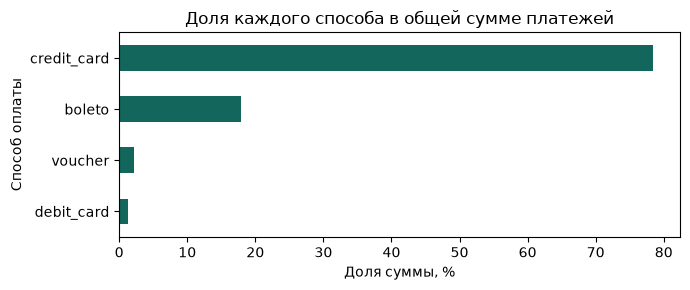

In [10]:
payments_sql = """
    SELECT p.payment_type, SUM(p.payment_value) AS payment_value
    FROM olist.order_payments p JOIN olist.orders o ON p.order_id = o.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY p.payment_type
    ORDER BY payment_value DESC
"""
payments = pd.read_sql(payments_sql, engine).set_index("payment_type")
payment_share = 100 * payments["payment_value"] / payments["payment_value"].sum()
ax = payment_share.sort_values().plot.barh(color="#13665c", figsize=(7, 3))
ax.set(title="Доля каждого способа в общей сумме платежей", xlabel="Доля суммы, %", ylabel="Способ оплаты")
plt.tight_layout()
plt.show()

На кредитные карты пришлось около 78,5 % суммы зарегистрированных оплат доставленных заказов. Заказ с ваучером и картой распределён между двумя способами по фактически оплаченным суммам.

## 6. Связаны ли плата за доставку и стоимость товаров

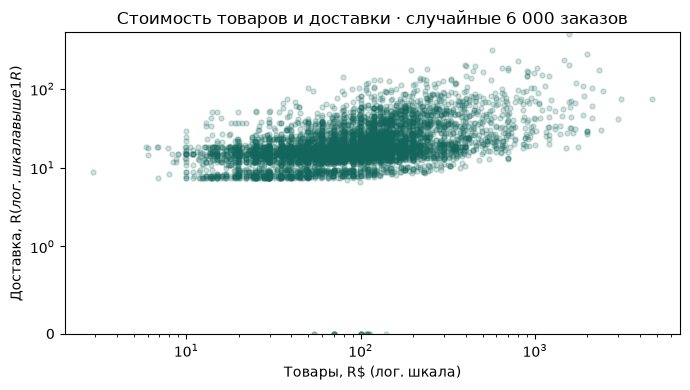

,revenue,freight_value
revenue,1.00,0.47
freight_value,0.47,1.00


In [11]:
points = orders.dropna(subset=["revenue", "freight_value"])
sample = points.sample(n=min(6000, len(points)), random_state=42)
ax = sample.plot.scatter(x="revenue", y="freight_value", color="#13665c", alpha=.2, s=13, figsize=(7, 4))
ax.set_xscale("log")
ax.set_yscale("symlog", linthresh=1)
ax.set_ylim(bottom=0)
ax.set(title="Стоимость товаров и доставки · случайные 6 000 заказов",
       xlabel="Товары, R$ (лог. шкала)", ylabel="Доставка, R$ (лог. шкала выше 1 R$)")
plt.tight_layout()
plt.show()
orders[["revenue", "freight_value"]].corr(method="spearman").round(3)

Корреляция Спирмена около 0,47. У более дорогих заказов доставка обычно дороже, но для одной и той же стоимости товаров тарифы сильно различаются.

## Главные находки

- Максимум по доставленным заказам наблюдается в ноябре 2017 года. Края ряда неполные.
- Срок половины доставок укладывается в 10 календарных дней. Долгое ожидание сдвигает среднее вверх.
- В группе с опозданием преобладают низкие оценки. Оценка есть только у покупателей, оставивших отзыв.
- `health_beauty` обгоняет `watches_gifts` по товарному обороту.
- Кредитная карта покрывает почти четыре пятых зафиксированной суммы платежей.
- Заказы с большей стоимостью товаров чаще имеют более дорогую доставку. Вес и маршрут тоже могут влиять на обе суммы.